> **Versi arsip ARIMAX-GARCH** (`arsip/arimax_garch/`, terpisah dari skripsi). Model standalone
> (LSTM, GRU) sama persis dengan skripsi: 1.523 hari, 1.218 data training, fold 486/730/974.
> Pada model hybrid (GARCH-LSTM, GARCH-GRU), kolom `garch_vol` berasal dari GARCH yang dipasang
> pada residual ARIMAX (notebook `01_arimax_garch_{E}`). Dua hari pertama tidak memiliki
> `garch_vol` (hari ke-1 tanpa log return, hari ke-2 tanpa log return eksogen hari sebelumnya),
> sehingga data hybrid berjumlah 1.521 hari: 1.216 data training (6 Januari 2020 sampai
> 10 Januari 2025) dan fold 484/728/972 dengan periode validasi yang sama. Data testing tetap
> 305 hari (13 Januari 2025 sampai 30 April 2026).

# 02 Pemodelan

Notebook ini melatih satu kombinasi model dan emiten (`metodologi.md` bagian 5
sampai 9): pembagian data, normalisasi, *hyperparameter tuning* dengan Optuna TPE
pada 3 fold *expanding window*, training final, lalu prediksi dan evaluasi pada
305 hari data testing.

Kedelapan notebook 02 identik; yang berbeda hanya sel parameter di bawah.
Model hybrid (GARCH-LSTM, GARCH-GRU) sama persis dengan model standalone, hanya
ditambah satu kolom fitur `garch_vol`.

In [1]:
EMITEN = "ANTM"        # ANTM / INCO
MODEL_TYPE = "LSTM"    # LSTM / GRU
USE_GARCH = True       # False = standalone, True = hybrid (tambah kolom garch_vol)

In [2]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # sebelum import torch, agar cuBLAS deterministik

import pickle
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import optuna
from sklearn.preprocessing import MinMaxScaler
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from IPython.display import display

MODEL_NAME = "GARCH-" + MODEL_TYPE if USE_GARCH else MODEL_TYPE
SEED = 42
WINDOW = 60
N_TRIALS = 50
MAX_EPOCHS = 200
PATIENCE = 10
ALPHA = 0.05                  # taraf signifikansi
LAG_ACF = 40
LAG_LJUNG_BOX = [10, 20]


def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

os.makedirs("outputs", exist_ok=True)
BERKAS_XLSX = "outputs/02_" + MODEL_NAME + "_" + EMITEN + ".xlsx"
tabel = {}   # seluruh tabel yang disimpan ke xlsx, sesuai urutan langkah

def tampil(df):
    # tampilkan 10 baris teratas dan 10 baris terbawah
    if len(df) <= 20:
        display(df)
    else:
        display(pd.concat([df.head(10), df.tail(10)]))

device: cuda


## 1. Dataset

Target (harga penutupan) berada di kolom pertama. Pada model hybrid, dua hari pertama
dibuang, lalu kolom `garch_vol` dibaca dari sheet `conditional_volatility` hasil notebook
`01_arimax_garch_{E}` (kolom `sigma`), digabung berdasarkan tanggal, dan diletakkan di
kolom terakhir.

| Model | Fitur ANTM | Fitur INCO |
|---|---|---|
| LSTM, GRU | antm, emas, nikel | inco, nikel |
| GARCH-LSTM, GARCH-GRU | antm, emas, nikel, garch_vol | inco, nikel, garch_vol |

In [3]:
data = pd.read_csv("data/data_" + EMITEN.lower() + ".csv")
data["Tanggal"] = pd.to_datetime(data["Tanggal"])

if USE_GARCH:
    data = data.iloc[2:].reset_index(drop=True)   # hybrid: dua hari pertama tidak memiliki garch_vol
    vol = pd.read_excel("outputs/01_arimax_garch_" + EMITEN + ".xlsx", sheet_name="conditional_volatility")
    vol = vol[["Tanggal", "sigma"]].rename(columns={"sigma": "garch_vol"})
    vol["Tanggal"] = pd.to_datetime(vol["Tanggal"])
    data = data.merge(vol, on="Tanggal", how="left")

assert len(data) == (1521 if USE_GARCH else 1523)
assert data.isna().sum().sum() == 0

FITUR = list(data.columns[1:])   # target di kolom pertama
TARGET = FITUR[0]
tabel["dataset"] = data
tampil(data)

,Tanggal,antm,emas,nikel,garch_vol
0,2020-01-06,885.0,1568.8,13820.00,2.815538
1,2020-01-07,875.0,1574.3,13935.00,2.916467
2,2020-01-08,905.0,1560.2,14050.00,2.839600
3,2020-01-09,880.0,1554.3,14085.00,2.895148
4,2020-01-10,885.0,1560.1,14190.00,2.902852
5,2020-01-13,870.0,1550.6,14095.00,2.791996
6,2020-01-14,850.0,1544.6,13870.00,2.770178
7,2020-01-15,835.0,1554.0,14320.00,2.718626
8,2020-01-16,845.0,1550.5,13775.00,2.651231
9,2020-01-17,840.0,1560.3,13910.00,2.552259


## 2. Pembagian data dan fold

Algoritma `metodologi.md` bagian 2: 1.218 data training (hybrid: 1.216) dan 305 data testing, lalu
3 fold *expanding window* dari data training. Data testing tidak dipakai sama
sekali selama tuning.

In [4]:
# pembagian dihitung pada 1.523 hari seperti skripsi; pada model hybrid, dua hari pertama yang
# dibuang dikurangkan dari data training, sehingga periode validasi dan testing tetap sama
N_ASLI = 1523
HARI_DIBUANG = 2 if USE_GARCH else 0
R_TEST = 0.2
R_VAL = 0.2

n_test = round(N_ASLI * R_TEST)          # 305
n_trainval_asli = N_ASLI - n_test        # 1.218

n_val = round(n_trainval_asli * R_VAL)   # 244
n_train = n_trainval_asli - n_val
daftar_fold = []
while n_val <= n_train:
    daftar_fold.append((n_train - HARI_DIBUANG, n_val))
    n_train = n_train - n_val
daftar_fold = sorted(daftar_fold)   # dari jumlah training terkecil

N = len(data)                 # 1.523 (standalone) atau 1.521 (hybrid)
n_trainval = N - n_test       # 1.218 (standalone) atau 1.216 (hybrid)
assert n_test == 305 and n_trainval == 1218 - HARI_DIBUANG

tanggal = data["Tanggal"]
pembagian_data = pd.DataFrame([
    ["Seluruh dataset", N, N / N * 100, 1, N, tanggal[0], tanggal[N - 1]],
    ["Training (train + validation)", n_trainval, n_trainval / N * 100, 1, n_trainval, tanggal[0], tanggal[n_trainval - 1]],
    ["Testing", n_test, n_test / N * 100, n_trainval + 1, N, tanggal[n_trainval], tanggal[N - 1]],
], columns=["jenis_data", "jumlah", "proporsi_persen", "data_ke_awal", "data_ke_akhir", "tanggal_awal", "tanggal_akhir"])

baris = []
for fold, (n_tr, n_v) in enumerate(daftar_fold, start=1):
    baris.append([fold, n_tr, 1, n_tr, tanggal[0], tanggal[n_tr - 1],
                  n_v, n_tr + 1, n_tr + n_v, tanggal[n_tr], tanggal[n_tr + n_v - 1]])
pembagian_fold = pd.DataFrame(baris, columns=[
    "fold", "jumlah_training", "training_data_ke_awal", "training_data_ke_akhir",
    "training_tanggal_awal", "training_tanggal_akhir", "jumlah_validation",
    "validation_data_ke_awal", "validation_data_ke_akhir",
    "validation_tanggal_awal", "validation_tanggal_akhir"])

tabel["pembagian_data"] = pembagian_data
tabel["pembagian_fold"] = pembagian_fold
display(pembagian_data)
display(pembagian_fold)

,jenis_data,jumlah,proporsi_persen,data_ke_awal,data_ke_akhir,tanggal_awal,tanggal_akhir
0,Seluruh dataset,1521,100.000000,1,1521,2020-01-06,2026-04-30
1,Training (train + validation),1216,79.947403,1,1216,2020-01-06,2025-01-10
2,Testing,305,20.052597,1217,1521,2025-01-13,2026-04-30


,fold,jumlah_training,training_data_ke_awal,training_data_ke_akhir,training_tanggal_awal,training_tanggal_akhir,jumlah_validation,validation_data_ke_awal,validation_data_ke_akhir,validation_tanggal_awal,validation_tanggal_akhir
0,1,484,1,484,2020-01-06,2021-12-27,244,485,728,2021-12-28,2022-12-23
1,2,728,1,728,2020-01-06,2022-12-23,244,729,972,2022-12-26,2023-12-29
2,3,972,1,972,2020-01-06,2023-12-29,244,973,1216,2024-01-02,2025-01-10


## 3. Normalisasi dan sliding window per fold

Min-Max Scaling $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$, dengan $x_{min}$ dan
$x_{max}$ dihitung **terpisah untuk setiap kolom** dan **hanya dari data training
fold tersebut**, lalu dipakai untuk mentransformasi data validasinya. Scaler kolom
target dipisah dari scaler fitur, sehingga prediksi dapat dikembalikan ke skala
harga asli. Nilai validasi dapat berada di luar [0, 1].

Sliding window 60 hari: masukan baris $i-60$ sampai $i-1$, target harga baris $i$.
Window pertama validasi mengambil 60 baris terakhir data training, sehingga
seluruh 244 hari validasi dapat diprediksi.

Normalisasi dan window tidak bergantung pada hyperparameter, sehingga cukup
disiapkan sekali untuk ketiga fold dan dipakai ulang oleh setiap trial (setara
dengan langkah 7-9 algoritma tuning).

In [5]:
def buat_window(nilai_fitur, nilai_target, awal, akhir):
    # masukan: baris i-60 sampai i-1, target: baris i, untuk i = awal sampai akhir-1
    X, y = [], []
    for i in range(awal, akhir):
        X.append(nilai_fitur[i - WINDOW:i])
        y.append(nilai_target[i])
    X = torch.tensor(np.array(X), dtype=torch.float32).to(device)
    y = torch.tensor(np.array(y), dtype=torch.float32).to(device)
    return X, y

In [6]:
data_fold = []
baris_minmax = []
for fold, (n_train, n_val) in enumerate(daftar_fold, start=1):
    bagian = data.iloc[:n_train + n_val]   # training + validation fold ini
    train = bagian.iloc[:n_train]

    scaler_fitur = MinMaxScaler().fit(train[FITUR].values)
    scaler_target = MinMaxScaler().fit(train[[TARGET]].values)
    nilai_fitur = scaler_fitur.transform(bagian[FITUR].values)
    nilai_target = scaler_target.transform(bagian[[TARGET]].values)

    X_train, y_train = buat_window(nilai_fitur, nilai_target, WINDOW, n_train)
    X_val, y_val = buat_window(nilai_fitur, nilai_target, n_train, n_train + n_val)
    assert len(X_val) == n_val

    data_fold.append({
        "X_train": X_train, "y_train": y_train, "X_val": X_val, "y_val": y_val,
        "scaler_target": scaler_target, "aktual_val": bagian[TARGET].values[n_train:],
    })
    for kolom, x_min, x_max in zip(FITUR, scaler_fitur.data_min_, scaler_fitur.data_max_):
        baris_minmax.append([fold, kolom, x_min, x_max])

    hasil_normalisasi = pd.DataFrame(nilai_fitur, columns=FITUR)
    hasil_normalisasi.insert(0, "Tanggal", bagian["Tanggal"].values)
    print("Fold", fold, ": training", n_train, "baris, validation", n_val, "baris, sesudah normalisasi")
    tampil(hasil_normalisasi)

minmax_fold = pd.DataFrame(baris_minmax, columns=["fold", "variabel", "min", "max"])
tabel["minmax_fold"] = minmax_fold
display(minmax_fold)

Fold 1 : training 484 baris, validation 244 baris, sesudah normalisasi


,Tanggal,antm,emas,nikel,garch_vol
0,2020-01-06,0.188951,0.153677,0.295938,0.176370
1,2020-01-07,0.185433,0.162975,0.307514,0.191791
2,2020-01-08,0.195989,0.139138,0.319090,0.180046
3,2020-01-09,0.187192,0.129163,0.322613,0.188533
4,2020-01-10,0.188951,0.138969,0.333182,0.189711
5,2020-01-13,0.183673,0.122908,0.323620,0.172773
6,2020-01-14,0.176636,0.112764,0.300971,0.169439
7,2020-01-15,0.171358,0.128656,0.346268,0.161562
8,2020-01-16,0.174877,0.122739,0.291409,0.151265
9,2020-01-17,0.173118,0.139307,0.304998,0.136142


Fold 2 : training 728 baris, validation 244 baris, sesudah normalisasi


,Tanggal,antm,emas,nikel,garch_vol
0,2020-01-06,0.188951,0.153677,0.057835,0.177907
1,2020-01-07,0.185433,0.162975,0.060097,0.193300
2,2020-01-08,0.195989,0.139138,0.062359,0.181577
3,2020-01-09,0.187192,0.129163,0.063048,0.190049
4,2020-01-10,0.188951,0.138969,0.065113,0.191223
5,2020-01-13,0.183673,0.122908,0.063245,0.174317
6,2020-01-14,0.176636,0.112764,0.058818,0.170990
7,2020-01-15,0.171358,0.128656,0.067671,0.163128
8,2020-01-16,0.174877,0.122739,0.056950,0.152849
9,2020-01-17,0.173118,0.139307,0.059605,0.137755


Fold 3 : training 972 baris, validation 244 baris, sesudah normalisasi


,Tanggal,antm,emas,nikel,garch_vol
0,2020-01-06,0.188951,0.150099,0.057835,0.228546
1,2020-01-07,0.185433,0.159181,0.060097,0.242990
2,2020-01-08,0.195989,0.135898,0.062359,0.231989
3,2020-01-09,0.187192,0.126156,0.063048,0.239939
4,2020-01-10,0.188951,0.135733,0.065113,0.241042
5,2020-01-13,0.183673,0.120046,0.063245,0.225177
6,2020-01-14,0.176636,0.110139,0.058818,0.222054
7,2020-01-15,0.171358,0.125661,0.067671,0.214676
8,2020-01-16,0.174877,0.119881,0.056950,0.205031
9,2020-01-17,0.173118,0.136063,0.059605,0.190867


,fold,variabel,min,max
0,1,antm,348.000000,3190.000000
1,1,emas,1477.900000,2069.400000
2,1,nikel,10880.000000,20814.500000
3,1,garch_vol,1.661237,8.206021
4,2,antm,348.000000,3190.000000
5,2,emas,1477.900000,2069.400000
6,2,nikel,10880.000000,61714.400000
7,2,garch_vol,1.648995,8.206021
8,3,antm,348.000000,3190.000000
9,3,emas,1477.900000,2083.500000


**Contoh perhitungan manual** $x'$ untuk satu observasi: kolom target pada hari
validasi pertama fold 1 (28 Desember 2021: data ke-487 pada standalone, data ke-485
pada hybrid), dengan $x_{min}$ dan $x_{max}$ dari data training fold 1 (486 data standalone,
484 data hybrid), dibandingkan dengan hasil `MinMaxScaler`.

In [7]:
n_train, n_val = daftar_fold[0]
x = data[TARGET][n_train]                  # hari validasi pertama fold 1 (28 Desember 2021)
x_min = data[TARGET][:n_train].min()
x_max = data[TARGET][:n_train].max()
x_manual = (x - x_min) / (x_max - x_min)
x_scaler = data_fold[0]["scaler_target"].transform([[x]])[0, 0]

contoh_normalisasi = pd.DataFrame([[1, data["Tanggal"][n_train], TARGET, x, x_min, x_max, x_manual, x_scaler]],
                                  columns=["fold", "Tanggal", "variabel", "x", "x_min", "x_max",
                                           "x_normalisasi_manual", "x_normalisasi_scaler"])
tabel["contoh_normalisasi"] = contoh_normalisasi
display(contoh_normalisasi)

,fold,Tanggal,variabel,x,x_min,x_max,x_normalisasi_manual,x_normalisasi_scaler
0,1,2021-12-28,antm,2260.0,348.0,3190.0,0.672766,0.672766


## 4. Arsitektur model dan fungsi training

Satu layer recurrent, keluaran *timestep* terakhir, dropout, lalu satu layer
linear dengan satu keluaran. Dropout diterapkan pada keluaran layer recurrent
sebelum layer dense (argumen `dropout` bawaan `nn.LSTM` tidak berpengaruh bila
jumlah layer hanya satu).

Fungsi kerugian MSE dan optimizer Adam. Batch diambil **berurutan tanpa
pengacakan**. Setiap epoch: model dilatih pada data training, lalu MSE validasi
dihitung dengan `model.eval()` (dropout tidak aktif). Training berhenti bila MSE
validasi tidak turun selama 10 epoch, lalu bobot dengan MSE validasi terkecil
dikembalikan. Seed di-set ulang setiap kali model diinisialisasi.

In [8]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, dropout):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.dropout(out)
        return self.fc(out)


class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, dropout):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        out = out[:, -1, :]
        out = self.dropout(out)
        return self.fc(out)

In [9]:
def latih_model(params, X_train, y_train, X_val, y_val):
    set_seed(SEED)
    if MODEL_TYPE == "LSTM":
        model = LSTMModel(len(FITUR), params["hidden_size"], params["dropout"]).to(device)
    else:
        model = GRUModel(len(FITUR), params["hidden_size"], params["dropout"]).to(device)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=params["learning_rate"])
    batch_size = params["batch_size"]

    history = []
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epoch_tanpa_perbaikan = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        # training: batch diambil berurutan, tanpa pengacakan
        model.train()
        total_loss = 0
        for awal in range(0, len(X_train), batch_size):
            xb = X_train[awal:awal + batch_size]
            yb = y_train[awal:awal + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss = total_loss + loss.detach() * len(xb)
        train_loss = (total_loss / len(X_train)).item()

        # validasi: dropout tidak aktif
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), y_val).item()
        history.append([epoch, train_loss, val_loss])

        # early stopping pada validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            epoch_tanpa_perbaikan = 0
        else:
            epoch_tanpa_perbaikan += 1
            if epoch_tanpa_perbaikan >= PATIENCE:
                break

    model.load_state_dict(best_state)   # bobot dengan validation loss terkecil
    history = pd.DataFrame(history, columns=["epoch", "train_loss", "val_loss"]).set_index("epoch")
    return model, best_val_loss, best_epoch, history


def prediksi_harga(model, X, scaler_target):
    model.eval()
    with torch.no_grad():
        pred = model(X).cpu().numpy()
    return scaler_target.inverse_transform(pred).ravel()   # kembali ke skala harga asli


def hitung_metrik(aktual, prediksi):
    rmse = np.sqrt(np.mean((aktual - prediksi) ** 2))
    mae = np.mean(np.abs(aktual - prediksi))
    mape = np.mean(np.abs((aktual - prediksi) / aktual)) * 100
    return rmse, mae, mape

## 5. Hyperparameter tuning (Optuna TPE)

| Parameter | Ruang pencarian |
|---|---|
| hidden_size | 32 sampai 128 (integer) |
| dropout | 0,1 sampai 0,5 |
| batch_size | 8 sampai 64 (integer) |
| learning_rate | 0,0001 sampai 0,001 (skala log) |

50 trial. Setiap trial dilatih pada ketiga fold dengan model baru dan seed tetap.
Objective trial = rata-rata MSE validasi terkecil ketiga fold (skala
ternormalisasi); hanya nilai ini yang menentukan hyperparameter terbaik. RMSE,
MAE, dan MAPE tiap fold dihitung pada skala harga asli (setelah *inverse
transform*) untuk pelaporan saja. Tabel `trials` berisi 50 x 3 = 150 baris.

In [10]:
baris_trials = []


def objective(trial):
    params = {
        "hidden_size": trial.suggest_int("hidden_size", 32, 128),
        "dropout": trial.suggest_float("dropout", 0.1, 0.5),
        "batch_size": trial.suggest_int("batch_size", 8, 64),
        "learning_rate": trial.suggest_float("learning_rate", 0.0001, 0.001, log=True),
    }
    daftar_error = []
    for fold, f in enumerate(data_fold, start=1):
        model, mse_val, best_epoch, _ = latih_model(params, f["X_train"], f["y_train"], f["X_val"], f["y_val"])
        daftar_error.append(mse_val)

        # evaluasi fold pada skala harga asli (hanya untuk pelaporan)
        pred_val = prediksi_harga(model, f["X_val"], f["scaler_target"])
        rmse, mae, mape = hitung_metrik(f["aktual_val"], pred_val)
        baris_trials.append([trial.number + 1, fold, params["hidden_size"], params["dropout"],
                             params["batch_size"], params["learning_rate"], mse_val, best_epoch, rmse, mae, mape])
    return np.mean(daftar_error)


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)

trials = pd.DataFrame(baris_trials, columns=["trial", "fold", "hidden_size", "dropout", "batch_size", "learning_rate",
                                             "mse_validasi", "best_epoch", "rmse", "mae", "mape"])
tabel["trials"] = trials
tampil(trials)

,trial,fold,hidden_size,dropout,batch_size,learning_rate,mse_validasi,best_epoch,rmse,mae,mape
0,1,1,68,0.480286,49,0.000397,0.010695,5,293.908106,236.058430,10.565500
1,1,2,68,0.480286,49,0.000397,0.000736,13,77.118855,66.493584,3.392248
2,1,3,68,0.480286,49,0.000397,0.001129,16,95.497911,74.145680,4.945242
3,2,1,47,0.162398,11,0.000735,0.015527,2,354.132125,288.874918,14.136835
4,2,2,47,0.162398,11,0.000735,0.000187,52,38.833318,30.394399,1.583372
5,2,3,47,0.162398,11,0.000735,0.000280,47,47.555979,36.822401,2.489653
6,3,1,90,0.383229,9,0.000933,0.029172,1,485.404627,425.028859,21.013768
7,3,2,90,0.383229,9,0.000933,0.000189,29,39.043157,30.378774,1.595448
8,3,3,90,0.383229,9,0.000933,0.000635,11,71.599868,56.993718,3.858796
9,4,1,112,0.184936,18,0.000153,0.011007,3,298.170437,223.622537,10.187896


In [11]:
trial_terbaik = study.best_trial.number + 1
params_terbaik = study.best_params

best_params = pd.DataFrame([[trial_terbaik, params_terbaik["hidden_size"], params_terbaik["dropout"],
                             params_terbaik["batch_size"], params_terbaik["learning_rate"], study.best_value]],
                           columns=["trial", "hidden_size", "dropout", "batch_size", "learning_rate",
                                    "rata_rata_mse_validasi"])
tabel["best_params"] = best_params
display(best_params)

cv_terbaik = trials[trials["trial"] == trial_terbaik][["fold", "mse_validasi", "best_epoch", "rmse", "mae", "mape"]]
tabel["cv_terbaik"] = cv_terbaik
display(cv_terbaik)

,trial,hidden_size,dropout,batch_size,learning_rate,rata_rata_mse_validasi
0,50,37,0.100309,44,0.000985,0.001284


,fold,mse_validasi,best_epoch,rmse,mae,mape
147,1,0.002943,6,154.176594,122.370777,5.968453
148,2,0.000376,29,55.081978,42.119135,2.184881
149,3,0.000533,18,65.602011,51.290177,3.446174


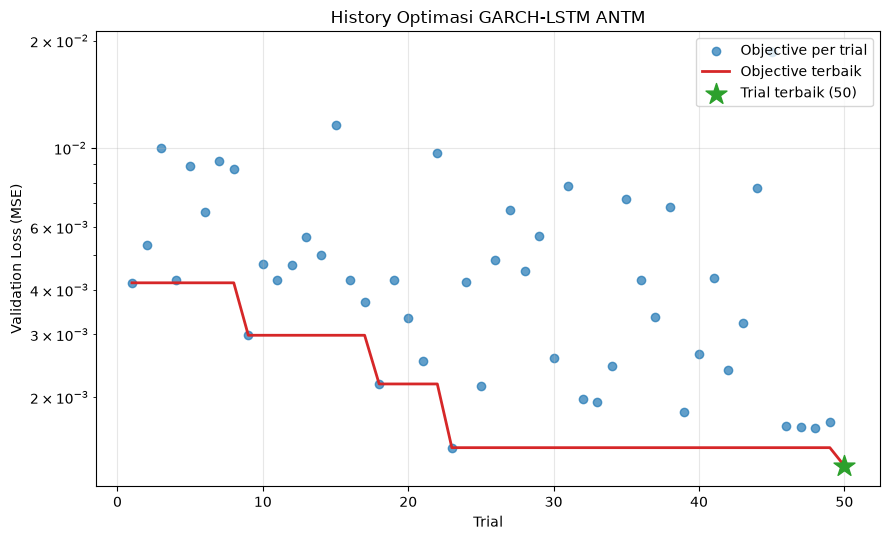

In [12]:
nomor_trial = [t.number + 1 for t in study.trials]
nilai_objective = [t.value for t in study.trials]
objective_terbaik = np.minimum.accumulate(nilai_objective)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(nomor_trial, nilai_objective, color="tab:blue", alpha=0.7, label="Objective per trial")
ax.plot(nomor_trial, objective_terbaik, color="tab:red", lw=2, label="Objective terbaik")
ax.scatter(trial_terbaik, study.best_value, color="tab:green", marker="*", s=250, zorder=5,
           label="Trial terbaik (" + str(trial_terbaik) + ")")
ax.set_yscale("log")
ax.set_title("History Optimasi " + MODEL_NAME + " " + EMITEN)
ax.set_xlabel("Trial")
ax.set_ylabel("Validation Loss (MSE)")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("outputs/gambar_history_optimasi_" + MODEL_NAME + "_" + EMITEN + ".png", dpi=300)
plt.show()

## 6. Training final

Tidak ada pencarian hyperparameter lagi. Data training (1.218; hybrid 1.216) dibagi
kronologis menjadi 974 (hybrid 972) data training final (melatih bobot) dan 244 data validation final
(*early stopping*), sama dengan fold 3.

1. MinMaxScaler di-fit **hanya pada 974 (hybrid 972) data training final**
2. Data validasi dan data testing ditransformasi dengan scaler yang sama
3. Sliding window 60 hari; window pertama validasi dan testing mengambil 60 baris
   terakhir dari bagian sebelumnya
4. Model diinisialisasi dengan hyperparameter terbaik dan seed tetap, lalu dilatih
   **satu kali** (maksimum 200 epoch, patience 10)

In [13]:
n_train_final, n_val_final = daftar_fold[-1]
assert n_train_final == 974 - HARI_DIBUANG and n_val_final == 244

train_final = data.iloc[:n_train_final]
scaler_fitur = MinMaxScaler().fit(train_final[FITUR].values)
scaler_target = MinMaxScaler().fit(train_final[[TARGET]].values)
nilai_fitur = scaler_fitur.transform(data[FITUR].values)    # seluruh baris dataset
nilai_target = scaler_target.transform(data[[TARGET]].values)

minmax_final = pd.DataFrame({"variabel": FITUR, "min": scaler_fitur.data_min_, "max": scaler_fitur.data_max_})
tabel["minmax_final"] = minmax_final
display(minmax_final)

data_normalisasi = pd.DataFrame(nilai_fitur, columns=FITUR)
data_normalisasi.insert(0, "Tanggal", data["Tanggal"])
tampil(data_normalisasi)

,variabel,min,max
0,antm,348.00000,3190.000000
1,emas,1477.90000,2083.500000
2,nikel,10880.00000,61714.400000
3,garch_vol,1.21859,8.206021


,Tanggal,antm,emas,nikel,garch_vol
0,2020-01-06,0.188951,0.150099,0.057835,0.228546
1,2020-01-07,0.185433,0.159181,0.060097,0.242990
2,2020-01-08,0.195989,0.135898,0.062359,0.231989
3,2020-01-09,0.187192,0.126156,0.063048,0.239939
4,2020-01-10,0.188951,0.135733,0.065113,0.241042
5,2020-01-13,0.183673,0.120046,0.063245,0.225177
6,2020-01-14,0.176636,0.110139,0.058818,0.222054
7,2020-01-15,0.171358,0.125661,0.067671,0.214676
8,2020-01-16,0.174877,0.119881,0.056950,0.205031
9,2020-01-17,0.173118,0.136063,0.059605,0.190867


In [14]:
X_train, y_train = buat_window(nilai_fitur, nilai_target, WINDOW, n_train_final)
X_val, y_val = buat_window(nilai_fitur, nilai_target, n_train_final, n_trainval)
X_test, y_test = buat_window(nilai_fitur, nilai_target, n_trainval, N)
assert len(X_val) == 244 and len(X_test) == 305

model, best_val_loss, best_epoch, history = latih_model(params_terbaik, X_train, y_train, X_val, y_val)
tabel["history_final"] = history.reset_index()
tampil(history.reset_index())

,epoch,train_loss,val_loss
0,1,0.319681,0.031066
1,2,0.068497,0.138862
2,3,0.043500,0.050712
3,4,0.029448,0.066310
4,5,0.029371,0.056652
5,6,0.025790,0.053804
6,7,0.022708,0.041679
7,8,0.018776,0.030414
8,9,0.016251,0.019854
9,10,0.012889,0.010348


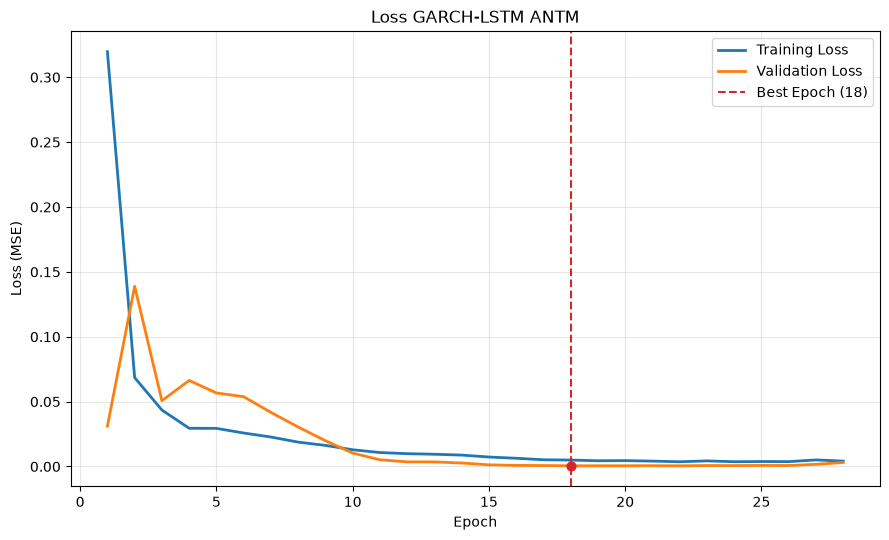

In [15]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(history.index, history["train_loss"], color="tab:blue", lw=2, label="Training Loss")
ax.plot(history.index, history["val_loss"], color="tab:orange", lw=2, label="Validation Loss")
ax.axvline(best_epoch, color="tab:red", ls="--", lw=1.5, label="Best Epoch (" + str(best_epoch) + ")")
ax.scatter(best_epoch, history.loc[best_epoch, "val_loss"], color="tab:red", s=40, zorder=5)
ax.set_title("Loss " + MODEL_NAME + " " + EMITEN)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (MSE)")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("outputs/gambar_loss_" + MODEL_NAME + "_" + EMITEN + ".png", dpi=300)
plt.show()

## 7. Prediksi dan evaluasi pada data testing

Model memprediksi 305 hari data testing. Prediksi dikembalikan ke skala harga asli
dengan *inverse transform* memakai scaler kolom target, lalu dihitung:

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2} \qquad MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad MAPE = \frac{1}{n}\sum_{i=1}^{n}\left|\frac{y_i - \hat{y}_i}{y_i}\right| \times 100\%$$

dengan $n = 305$, pada skala harga asli (Rupiah). Kolom `selisih` = aktual -
prediksi, dan `error_persen` = |selisih / aktual| x 100.

In [16]:
prediksi = prediksi_harga(model, X_test, scaler_target)
aktual = data[TARGET].values[n_trainval:]

hasil_prediksi = pd.DataFrame({
    "Tanggal": data["Tanggal"].values[n_trainval:],
    "aktual": aktual,
    "prediksi": prediksi,
})
hasil_prediksi["selisih"] = hasil_prediksi["aktual"] - hasil_prediksi["prediksi"]
hasil_prediksi["error_persen"] = (hasil_prediksi["selisih"] / hasil_prediksi["aktual"]).abs() * 100
tabel["prediksi"] = hasil_prediksi
tampil(hasil_prediksi)

rmse, mae, mape = hitung_metrik(aktual, prediksi)
metrik = pd.DataFrame([[rmse, mae, mape]], columns=["rmse", "mae", "mape"])
tabel["metrik"] = metrik
display(metrik)

,Tanggal,aktual,prediksi,selisih,error_persen
0,2025-01-13,1480.0,1443.852417,36.147583,2.442404
1,2025-01-14,1520.0,1442.071899,77.928101,5.126849
2,2025-01-15,1530.0,1445.671753,84.328247,5.511650
3,2025-01-16,1520.0,1455.039551,64.960449,4.273714
4,2025-01-17,1520.0,1462.636108,57.363892,3.773940
5,2025-01-20,1510.0,1466.353149,43.646851,2.890520
6,2025-01-21,1510.0,1466.065430,43.934570,2.909574
7,2025-01-22,1520.0,1467.875366,52.124634,3.429252
8,2025-01-23,1490.0,1468.422485,21.577515,1.448155
9,2025-01-24,1490.0,1460.999390,29.000610,1.946350


,rmse,mae,mape
0,550.010407,443.568595,13.376854


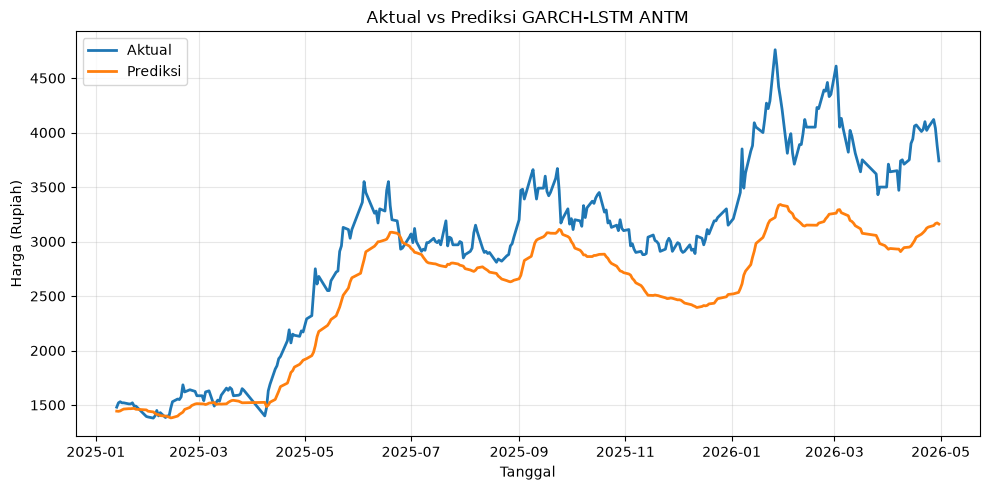

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hasil_prediksi["Tanggal"], hasil_prediksi["aktual"], color="tab:blue", lw=2, label="Aktual")
ax.plot(hasil_prediksi["Tanggal"], hasil_prediksi["prediksi"], color="tab:orange", lw=2, label="Prediksi")
ax.set_title("Aktual vs Prediksi " + MODEL_NAME + " " + EMITEN)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Harga (Rupiah)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("outputs/gambar_prediksi_" + MODEL_NAME + "_" + EMITEN + ".png", dpi=300)
plt.show()

## 8. Karakteristik residual

Residual adalah selisih harga aktual dengan prediksi pada 305 hari data testing (kolom
`selisih` pada tabel prediksi), dalam rupiah. Residual yang baik tidak lagi memiliki
pola atau autokorelasi. Bila masih ada autokorelasi, berarti masih ada informasi dari
hari-hari sebelumnya yang belum tertangkap model.

1. Plot residual terhadap waktu, untuk melihat pola secara visual
2. ACF residual sampai lag 40
3. Uji Ljung-Box lag 10 dan 20. $H_0$: tidak ada autokorelasi pada residual. $H_0$
   ditolak bila p-value < 0,05.

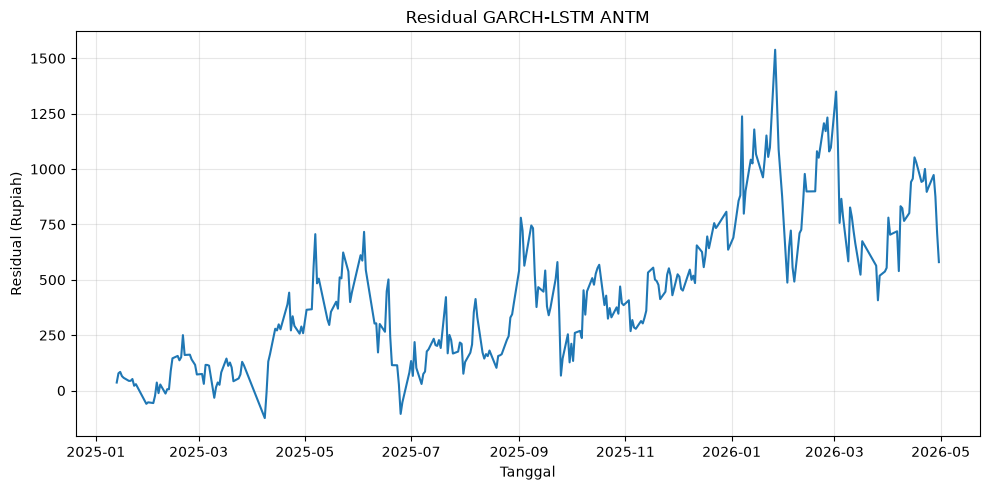

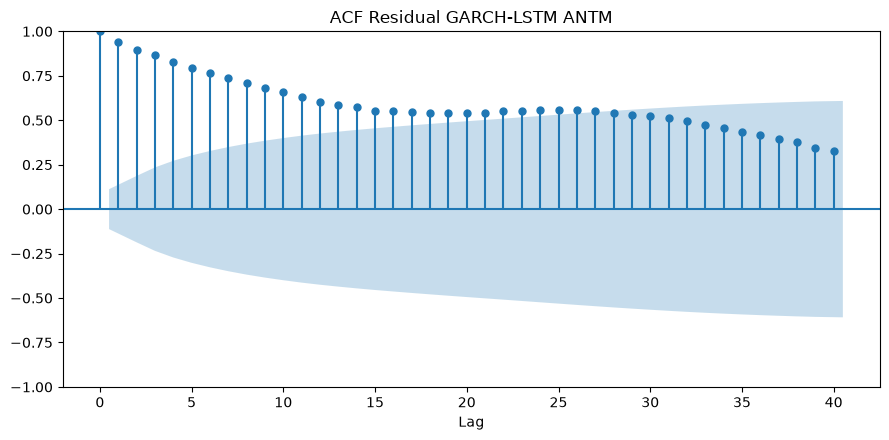

In [18]:
residual = hasil_prediksi["selisih"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hasil_prediksi["Tanggal"], residual, color="tab:blue")
ax.set_title("Residual " + MODEL_NAME + " " + EMITEN)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Residual (Rupiah)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/gambar_residual_" + MODEL_NAME + "_" + EMITEN + ".png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_acf(residual, lags=LAG_ACF, ax=ax, title="ACF Residual " + MODEL_NAME + " " + EMITEN)
ax.set_xlabel("Lag")
plt.tight_layout()
plt.savefig("outputs/gambar_acf_residual_" + MODEL_NAME + "_" + EMITEN + ".png", dpi=300)
plt.show()

In [19]:
ljung_box = acorr_ljungbox(residual, lags=LAG_LJUNG_BOX)
baris = []
for lag in LAG_LJUNG_BOX:
    p_value = ljung_box.loc[lag, "lb_pvalue"]
    keputusan = "ada autokorelasi" if p_value < ALPHA else "tidak ada autokorelasi"
    baris.append([lag, ljung_box.loc[lag, "lb_stat"], p_value, keputusan])
ljung_box_residual = pd.DataFrame(baris, columns=["lag", "statistik", "p_value", "keputusan"])
tabel["ljung_box_residual"] = ljung_box_residual
display(ljung_box_residual)

,lag,statistik,p_value,keputusan
0,10,1959.858437,0.0,ada autokorelasi
1,20,2998.583475,0.0,ada autokorelasi


## 9. Simpan tabel

Seluruh tabel disimpan utuh ke `outputs/02_{MODEL_NAME}_{EMITEN}.xlsx`, satu tabel
per sheet sesuai urutan langkah.

In [20]:
with pd.ExcelWriter(BERKAS_XLSX, date_format="YYYY-MM-DD", datetime_format="YYYY-MM-DD") as writer:
    for nama_sheet in tabel:
        tabel[nama_sheet].to_excel(writer, sheet_name=nama_sheet, index=False)

In [21]:
# simpan model final (bobot jaringan) serta scaler fitur dan target,
# agar model dapat dipakai lagi tanpa melatih ulang
os.makedirs("outputs/model", exist_ok=True)
nama = MODEL_NAME + "_" + EMITEN
torch.save(model.state_dict(), "outputs/model/model_" + nama + ".pt")
with open("outputs/model/scaler_fitur_" + nama + ".pkl", "wb") as f:
    pickle.dump(scaler_fitur, f)
with open("outputs/model/scaler_target_" + nama + ".pkl", "wb") as f:
    pickle.dump(scaler_target, f)